<a href="https://colab.research.google.com/github/ichwan21/ichwan-AE/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [ ]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [ ]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [ ]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [ ]:
#PROBLEM STATEMENT
#We want to know whether electric bikes are used for longer trips than standard bikes,
#and whether that differs by zone.
#Please give us the average trip duration by bike type and by the zone of the start station.

#1.A. Understanding the Data: Getting a General Overview of the Dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


tables["bikes"]
tables["stations"]
trips.head() #understanding the entries of the table
trips.shape  #understanding the total number of rows

#RESULT (1.A)
#UNDERSTANDING OF THE DATA: The dataset contains 612 entries, with each row representing a bike trip. The trips table records the trip ID, bike ID, starting station, ending station, start time, trip duration, and user type.


#1.B. Data Validation: Finding Null values, Duplicates, outier, inconsistent datatype, etc
#1.B.i Null value = 30 missing values out of 612 trip (4,9%) ; The duration_min column contains 30 missing values out of 612 trips (4.90%). The missingness was investigated against selected trip attributes, but no clear pattern has yet been established.
trips.info()  #first glance of the null value and datatype (observation: there are null values in duration)
trips[trips.isna().any(axis=1)] #further investigation on how many missing value and the percentage
trips.isna().sum()
(trips.isna().mean() * 100).round(2)

#1.B.ii Duplicate values = There are 12 duplicate records with identical values across all columns, including trip_id
trips.duplicated().sum()
trips[trips.duplicated(keep=False)]

#1.B.iii Out of Range Value = 3 outliers for "duration_min" are considered invalid because the expected end time calculated from its recorded start time and duration is later than the start time of the next recorded trip for the same bike
trips.describe() # statsiti information for "duration_min" (observation: Potential outliers after comparing the maximum value of 2880 againts 75% percentile of 22)
trips.nlargest(10, "duration_min") #there are 3 outliers with duration_min >>>>> 75th percentila
sns.boxplot(data=trips, y='duration_min')
plt.show #plotting the boxplot showing the outlier is waaaaay over the 75th percentile
trips


#asking chat gpt to check if the the start time + duration > start date of the next trip from the same bike; convert start time to datetime type first (be carefull with the mixed of format)
#The three potential outliers (T0081, T0143, and T0284) have temporal inconsistencies.
#For each trip, the expected end time calculated from its recorded start time and duration is later than the start time of the next recorded trip for the same bike.
target_ids = ["T0081", "T0143", "T0284"]

# Convert mixed date formats to datetime
trips["start_time"] = pd.to_datetime(
    trips["start_time"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Sort all trips and identify the next trip for the same bike
ordered = trips.sort_values(["bike_id", "start_time"]).copy()

ordered["next_trip_start"] = (
    ordered.groupby("bike_id")["start_time"].shift(-1)
)

# Select only the specified trip IDs
check = ordered[ordered["trip_id"].isin(target_ids)].copy()

# Calculate expected end time
check["expected_end_time"] = (
    check["start_time"]
    + pd.to_timedelta(check["duration_min"], unit="m")
)

# Flag potential time conflicts
check["time_conflict"] = (
    (check["expected_end_time"] > check["next_trip_start"])
    & check["expected_end_time"].notna()
    & check["next_trip_start"].notna()
)

check[[
    "trip_id", "bike_id", "start_time", "duration_min",
    "expected_end_time", "next_trip_start", "time_conflict"
]]


#1.B.iv Investigating the datatype : (1) datatype for start_time is object; (2)user_type contains inconsisten categorical value
trips.info() #start_time showing datatype, which is not optimum for time analysis
trips['user_type'].unique() #column contains inconsistent categorical values due to differences in capitalization and trailing whitespace => array(['Casual', 'CASUAL', 'Member', 'MEMBER', 'Casual', 'CASUAL', 'member' 'casual'], dtype=object)





array(['Casual', 'CASUAL', 'Member', 'MEMBER', 'Casual ', 'member',
       'casual'], dtype=object)

## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

,trip_id,bike_id,duration_min
80,T0081,B010,2880.0
143,T0143,B020,1440.0
287,T0284,B046,1440.0


Rows remaining: 597
Missing durations: 30
Maximum duration: 90.0
Exact duplicate rows: 0


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
127,T0127,B025,S08,S09,2025-03-07 09:01:00,90.0,Member
357,T0352,B042,S03,S02,2025-03-19 08:59:00,67.0,Member
326,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member
520,T0512,B045,S07,S04,2025-03-26 18:32:00,51.0,Member
37,T0038,B016,S12,S09,2025-03-02 12:23:00,50.0,Casual
262,T0260,B025,S04,S04,2025-03-15 07:29:00,46.0,Member
268,T0266,B046,S11,S01,2025-03-15 13:53:00,46.0,Member
163,T0163,B040,S08,S02,2025-03-09 11:27:00,41.0,Member
234,T0232,B054,S09,S09,2025-03-13 08:40:00,41.0,Member
280,T0278,B032,S01,S01,2025-03-15 17:41:00,41.0,Member


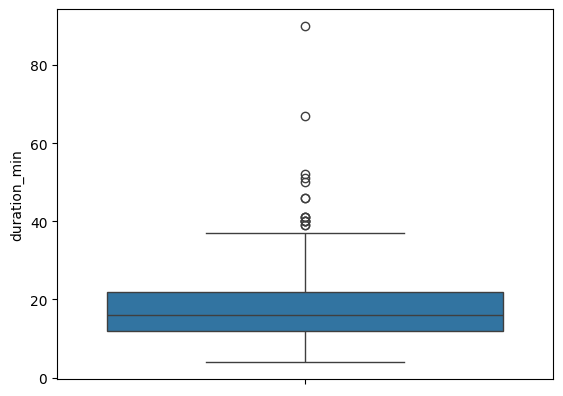

In [ ]:
#Problem: 1.B.iv Investigating the datatype : (1) datatype for start_time is object; (2)user_type contains inconsisten categorical value
#Solution (1): Change the datatype for start_time from object to timedate for enabling time based analysis which is usefull for analyzing the outliers in 1.B.iii (convertion has been done thanks to chatgpt, ref to 1.B.iii)
#Solution (2): change the user_type by converting ['Casual', 'CASUAL','Casual', 'CASUAL','casual] -> ['Casual'] and ['Member', 'MEMBER','member'] -> ['Member']. Reason: consistency

#asking chat gpt using prompt: change the user_type by converting ['Casual', 'CASUAL','Casual', 'CASUAL','casual] -> ['Casual'] and ['Member', 'MEMBER','member'] -> ['Member']
trips["user_type"] = (
    trips["user_type"]
    .str.strip()
    .str.lower()
    .str.title()
)

trips["user_type"].unique() #Result: array(['Casual', 'Member'], dtype=object)
trips.info() #validate the structure once agein


#Problem: 1.B.i Null value = 30 missing values out of 612 trip (4,9%) ; The duration_min column contains 30 missing values out of 612 trips (4.90%). The missingness was investigated against selected trip attributes, but no clear pattern has yet been established
#Solution : Leave as it is

#1.B.ii Duplicate values = There are 12 duplicate records with identical values across all columns, including trip_id
#Solution : Remove duplicates from all rows

#asking chatgpt using prompt: how to remove 12 duplicate records with identical values across all columns, including trip_id
# Check duplicates before removal
print("Before:", len(trips))
print("Duplicate rows:", trips.duplicated().sum())

# Remove exact duplicate records
trips = trips.drop_duplicates().copy()

# Verify the result
print("After:", len(trips))
print("Remaining duplicate rows:", trips.duplicated().sum())  #Result : Before: 612; Duplicate rows: 12 After: 600; Remaining duplicate rows: 0


#Problem: 1.B.iii Out of Range Value = 3 outliers. Analysis: Those 3 outliers for "duration_min" are considered invalid because the expected end time calculated from its recorded start time and duration is later than the start time of the next recorded trip for the same bike
#Solution : Remove 3 Outliers

#asking chatgpt using prompt: Removing 3 outliers (the top 3 of the maximum duration time), validate the result after deletion
# 1. Inspect the three longest trips before deletion
display(trips.nlargest(3, "duration_min")[
    ["trip_id", "bike_id", "duration_min"]
])

# 2. Remove the three longest-duration records
outlier_ids = trips.nlargest(3, "duration_min").index
trips = trips.drop(index=outlier_ids).copy()

# 3. Validate the result
print("Rows remaining:", len(trips))
print("Missing durations:", trips["duration_min"].isna().sum())
print("Maximum duration:", trips["duration_min"].max())
print("Exact duplicate rows:", trips.duplicated().sum())

# 4. Inspect the new top 10 durations
display(trips.nlargest(10, "duration_min"))

# 5. Replot the boxplot
sns.boxplot(data=trips, y="duration_min")
plt.show()





## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [ ]:
#Asking chat gpt: join tables to answer the problem statement: We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the average trip duration by bike type and by the zone of the start station.
#(Note: Join the tables and calculate the answer. Note how many rows you expect after each join, then check.)


# Prepare the reference tables
bikes = tables["bikes"].copy()
stations = tables["stations"].copy()

# Check starting row count
print("Trips before joins:", len(trips))

# Join trips with bikes
trips_bikes = trips.merge(
    bikes[["bike_id", "bike_type"]],
    on="bike_id",
    how="left",
    validate="many_to_one"
)

print("After joining bikes:", len(trips_bikes))

# Join with stations using the starting station ID
trips_bikes_stations = trips_bikes.merge(
    stations[["station_id", "zone"]].rename(
        columns={
            "station_id": "start_station_id",
            "zone": "start_zone"
        }
    ),
    on="start_station_id",
    how="left",
    validate="many_to_one"
)

print("After joining stations:", len(trips_bikes_stations))

Validate:

print(
    "Missing bike type after join:",
    trips_bikes_stations["bike_type"].isna().sum()
)

print(
    "Missing start zone after join:",
    trips_bikes_stations["start_zone"].isna().sum()
)


#calculate
summary = (
    trips_bikes_stations
    .dropna(subset=["bike_type", "start_zone", "duration_min"])
    .groupby(["bike_type", "start_zone"], as_index=False)
    .agg(
        number_of_trips=("trip_id", "size"),
        average_duration_min=("duration_min", "mean")
    )
)

summary["average_duration_min"] = (
    summary["average_duration_min"].round(2)
)

summary

#ADDITIONAL CLEANUP: WE NEED TO NORMALIZE / STANDARDIZE  bike_type
#ask chat gpt: show the uniqe character in bike_type

tables["bikes"]["bike_type"].unique()

#result: array(['Standard', 'Electric ', 'electric', 'STANDARD', 'standard','Electric', 'E-bike'], dtype=object)

#ask chat gpt : change the bike_type by converting ['Electric ', 'electric','Electric', 'E-bike'] -> ['Electric'] and ['Standard', 'STANDARD','standard'] -> ['Standard']. validate

# 1. Standardise bike_type
bikes = tables["bikes"].copy()

bikes["bike_type"] = (
    bikes["bike_type"]
    .str.strip()
    .str.lower()
    .replace({
        "electric": "Electric",
        "e-bike": "Electric",
        "standard": "Standard"
    })
)

# 2. Validate the changes
print("Unique bike types:", bikes["bike_type"].unique())
print("\nFrequency of each bike type:")
print(bikes["bike_type"].value_counts(dropna=False))



#RE-RUN AGGREGATION
#asking chat gpt: re-run the aggregation

# 1. Join trips with the cleaned bikes table
trips_bikes = trips.merge(
    bikes[["bike_id", "bike_type"]],
    on="bike_id",
    how="left",
    validate="many_to_one"
)

# 2. Join with stations using the starting station
trips_bikes_stations = trips_bikes.merge(
    tables["stations"][["station_id", "zone"]].rename(
        columns={
            "station_id": "start_station_id",
            "zone": "start_zone"
        }
    ),
    on="start_station_id",
    how="left",
    validate="many_to_one"
)

# 3. Check row counts and unmatched values
print("Trips:", len(trips))
print("After bikes join:", len(trips_bikes))
print("After stations join:", len(trips_bikes_stations))
print("Missing bike types:", trips_bikes_stations["bike_type"].isna().sum())
print("Missing start zones:", trips_bikes_stations["start_zone"].isna().sum())

# 4. Calculate trip count and average duration
summary = (
    trips_bikes_stations
    .dropna(subset=["bike_type", "start_zone", "duration_min"])
    .groupby(["bike_type", "start_zone"], as_index=False)
    .agg(
        number_of_trips=("trip_id", "size"),
        average_duration_min=("duration_min", "mean")
    )
)

summary["average_duration_min"] = summary["average_duration_min"].round(2)

# 5. Display the final table
summary

Trips: 597
After bikes join: 597
After stations join: 597
Missing bike types: 0
Missing start zones: 0


,bike_type,start_zone,number_of_trips,average_duration_min
0,Electric,Centre,81,14.51
1,Electric,East,11,15.73
2,Electric,North,23,15.96
3,Electric,South,24,13.42
4,Electric,West,22,15.68
5,Standard,Centre,215,18.93
6,Standard,East,20,19.50
7,Standard,North,39,20.36
8,Standard,South,59,19.47
9,Standard,West,73,19.82


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

In [ ]:
from numpy._core import records
1. Check row counts and join completeness

print("Trips before joins:", len(trips))
print("After bikes join:", len(trips_bikes))
print("After stations join:", len(trips_bikes_stations))

print("Missing bike types:",
      trips_bikes_stations["bike_type"].isna().sum())
print("Missing start zones:",
      trips_bikes_stations["start_zone"].isna().sum())
#RESULT
#Trips before joins: 597
#After bikes join: 597
#After stations join: 597
#Missing bike types: 0
#Missing start zones: 0


2. Spot check a few records
trips_bikes_stations[
    ["trip_id", "bike_id", "bike_type",
     "start_station_id", "start_zone", "duration_min"]
].sample(5, random_state=42)

3. Recalculate one average independently
# Calculate the average from the joined table
check_data = trips_bikes_stations[
    (trips_bikes_stations["bike_type"] == "Electric") &
    (trips_bikes_stations["start_zone"] == "Centre") &
    (trips_bikes_stations["duration_min"].notna())
]

mean_joined = check_data["duration_min"].mean()
count_joined = len(check_data)

# Compare against the summary table
mean_summary = summary.loc[
    (summary["bike_type"] == "Electric") &
    (summary["start_zone"] == "Centre"),
    "average_duration_min"
].iloc[0]

print("Trip count:", count_joined)
print("Recalculated average:", round(mean_joined, 2))
print("Summary average:", mean_summary)
print("Match:", round(mean_joined, 2) == mean_summary)


#result
#Trip count: 81
#Recalculated average: 14.51
#Summary average: 14.51
#Match: True

Trip count: 81
Recalculated average: 14.51
Summary average: 14.51
Match: True


## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*



> Add blockquote



## 6. What I could not verify

*What remains unchecked? What would you do next?*